# <span style="color: #32CD32;">Библеотеки для анализа</span>

In [1]:
import pandas as pd
import numpy as np


# <span style="color: #32CD32;">Подготовка данных:</span>
- Считываем актуальные данные из 8-го отчёт
- Считывает ретро данные из 13-го отчёта
- Делаем расчёт Стоимости ЕРС с учетом групп продуктов/групп каналов/продажи и сопровождения
- Считаем среднее продукта
- Минуса сразу заменяем на среднее продукта

  ### Считываем данные 

In [2]:
#Названия столбцов  (создание списка - 12 строк)
df_columns = ['Группа. Продукт ЕК', 'Группа текст','Драйвер', 'Драйвер текст','Категория расходов','Сегмент', 'Сегмент текст', 
              'Канал продажи','Канал продажи текст','Расход, руб.','Драйвер,шт.','Стоимость ЕРС'] 

#Получение данных из экселя (текущий расчет)
#sheet_name - название листа, names (названия колонок) описаны выше,  
#header - с какой строки нужно начинать считывать
df = pd.read_excel('Новая таблица.xlsx', sheet_name = 'Лист1', names = df_columns, header = 2)  

#Названия столбцов (создание списка - 10 строк)
df_retro_columns = ['Группа. Продукт ЕК', 'Группа текст','Драйвер', 'Драйвер текст','Категория расходов','Сегмент', 'Сегмент текст', 
              'Канал продажи','Канал продажи текст','Расход, руб.','Драйвер,шт.','Стоимость ЕРС ретро']

#Получение данных из экселя (прошлый расчет)
#sheet_name - название листа, names (названия колонок) описаны выше,  
#header - с какой строки нужно начать считывать
df_retro = pd.read_excel('Новая таблица.xlsx', sheet_name = 'Лист2', names = df_retro_columns, header = 2)



In [3]:
channel_groups = {
    5 : ["55", "56"],     
    6 : ["65", "67"]}

def get_channel_group(channel):
    for group_name, channels in channel_groups.items():
        if channel in channels:
            return group_name
    return channel  

df['Группы для каналов'] = df['Канал продажи'].apply(get_channel_group)


In [4]:
df_result = df.copy()
for col in ['Группа. Продукт ЕК', 'Сегмент', 'Канал продажи', 'Драйвер']:
    df_result[col] = df_result[col].astype(str).str.replace(' ', '').str.replace('\n', '')
    df_retro[col] = df_retro[col].astype(str).str.replace(' ', '').str.replace('\n', '')

### Объединяем в один датафрейм

In [5]:
df_result = df_result.merge(df_retro[['Группа. Продукт ЕК', 'Драйвер','Сегмент','Канал продажи','Категория расходов','Стоимость ЕРС ретро']], 
              on=['Группа. Продукт ЕК','Драйвер', 'Сегмент', 'Канал продажи', 'Категория расходов'], 
              how='left')

### Расчёт Стоиомости ЕРС по алгоритму 13-й витрины

In [6]:
def calculate_cost(df, group_col='Группа. Продукт ЕК', deal_type_col='Категория расходов',
                   segment_col='Сегмент', channel_col='Группы для каналов',
                   expenses_col='Расход, руб.', deals_col='Драйвер,шт.'):

    # Создаём копию
    df_result = df.copy()
    
    # ПРЕОБРАЗУЕМ ТИПЫ ДОГОВОРА
    # 'Продажа' -> 1, 'Сопровождение' -> 2
    deal_type_mapping = {
        'Продажа': '1',
        'Сопровождение': '2'
    }
    
    if deal_type_col in df_result.columns:
        df_result[deal_type_col] = df_result[deal_type_col].map(deal_type_mapping).fillna(df_result[deal_type_col]).astype(str)

    # Разделяем данные по типам договоров
    df_type_1 = df_result[df_result[deal_type_col] == '1'].copy()
    df_type_2 = df_result[df_result[deal_type_col] == '2'].copy()

    # ============================================
    # Категория расходов 1 (с учётом каналов)
    # ============================================
    
    if len(df_type_1) > 0:
        
        group_cols_1 = [group_col, deal_type_col, segment_col, channel_col]
        
        agg_1 = df_type_1.groupby(group_cols_1).agg(
            total_expenses=(expenses_col, 'sum'),
            total_deals=(deals_col, 'sum')
        ).reset_index()
        
        agg_1['Себестоимость'] = agg_1['total_expenses'] / agg_1['total_deals']

        df_type_1 = df_type_1.drop(
            columns=['Себестоимость'],
            errors='ignore'
        )

        # Присоединяем рассчитанную себестоимость
        df_type_1 = df_type_1.merge(
            agg_1[group_cols_1 + ['Себестоимость']],
            on=group_cols_1,
            how='left',
            validate='many_to_one'
        )

    # ============================================
    # Категория расходов 2 (без учёта каналов)
    # ============================================
    
    if len(df_type_2) > 0:

        group_cols_2 = [group_col, deal_type_col, segment_col]
        
        agg_2 = df_type_2.groupby(group_cols_2).agg(
            total_expenses=(expenses_col, 'sum'),
            total_deals=(deals_col, 'sum')
        ).reset_index()
        
        agg_2['Себестоимость'] = agg_2['total_expenses'] / agg_2['total_deals']

        df_type_2 = df_type_2.drop(
            columns=['Себестоимость'],
            errors='ignore'
        )

        # Присоединяем рассчитанную себестоимость
        df_type_2 = df_type_2.merge(
            agg_2[group_cols_2 + ['Себестоимость']],
            on=group_cols_2,
            how='left',
            validate='many_to_one'
        )

    df_result = pd.concat([df_type_1, df_type_2], ignore_index=True)
    

    return df_result

In [7]:
df_result = calculate_cost(df_result)

### Расчёт среднего продукта, которое в последнствии будет служить заменой для выбросов
- Вариант 1 -> Это стоимость продукта
- Вариант 2 -> Это стоимость сегмента в продукте

In [8]:
def calculate_cost_variants(df, group_col='Группа. Продукт ЕК', deal_type_col='Категория расходов',
                            segment_col='Сегмент', channel_col='Группы для каналов',
                            expenses_col='Расход, руб.', deals_col='Драйвер,шт.'):

    # Создаём копию
    df_result = df.copy()
    
    # Приводим Категория расходов к строковому формату (если ещё не приведён)
    df_result[deal_type_col] = df_result[deal_type_col].astype(str)

    # ============================================
    # ВАРИАНТ 1: Группа + Категория расходов
    # ============================================

    group_cols_1 = [group_col, deal_type_col]
    
    var1_agg = df_result.groupby(group_cols_1).agg(
        total_expenses=(expenses_col, 'sum'),
        total_deals=(deals_col, 'sum')
    ).reset_index()
    
    var1_agg['Среднее продукт'] = var1_agg['total_expenses'] / var1_agg['total_deals']
    
    # Присоединяем к результату
    df_result = df_result.merge(
        var1_agg[group_cols_1 + ['Среднее продукт']],
        on=group_cols_1,
        how='left'
    )
    

    # ============================================
    # ВАРИАНТ 2: Группа + Категория расходов + Сегмент
    # ============================================

    group_cols_2 = [group_col, deal_type_col, segment_col]
    
    var2_agg = df_result.groupby(group_cols_2).agg(
        total_expenses=(expenses_col, 'sum'),
        total_deals=(deals_col, 'sum')
    ).reset_index()
    
    var2_agg['Среднее сегмент'] = var2_agg['total_expenses'] / var2_agg['total_deals']
    
    # Присоединяем к результату
    df_result = df_result.merge(
        var2_agg[group_cols_2 + ['Среднее сегмент']],
       on=group_cols_2,
        how='left'
    )

    
    
    return df_result

In [9]:
df_result = calculate_cost_variants(df_result)

### Заменяем минуса на стоимость продукта без детализированных расзрезов 
Для это создаёт технический столбец, изначальные стоимости не заменяются для ручной проверки, если потребуется

In [10]:
def add_adjusted_cost(df, 
                      cost_col='Себестоимость',
                      replacement_col='Среднее продукт',
                      adjusted_col='Себестоимость_для_IQR'):
    
    df_result = df.copy()
    
    # Создаём колонку со скорректированной себестоимостью
    df_result[adjusted_col] = df_result[cost_col].copy()
    
    # Заменяем отрицательные значения
    mask_negative = df_result[cost_col] < 0
    df_result.loc[mask_negative, adjusted_col] = df_result.loc[mask_negative, replacement_col]
 # ← переименовано
    return df_result

In [11]:
df_result = add_adjusted_cost(df_result)

# <span style="color: #32CD32;">Выявление выбросов и их устранение</span>


- k_values -> значения k, который влияет на ширину диапозона, чем меньше значение k, тем меньше диапозон
- category_k_map -> словарь маппинга, меппинг уже настроен, изменения k_values автоматически отразятся 
- expensive_segments -> самые дорогие сегменты
- medium_segments -> средний ценовой диапозон
- все отсальные сегменты, которые не отражены в списке будут попадать в категорию other отдельно их записывать никак не нужно
- df_result = calculate_iqr_...(df_result, k_values, ...) - данная строка вызывает срабатывание функции, для всех функций вызов идентичен, меняется только количество переменных, которые можно передавать
- k_values -> передаётся только для функций по расчёту IQR
- category_k_map, expensive|medium_segments для алгоритма по устранению выбросов
- *excluded_segments* -> при необходимости можно задавать другие сегменты в любой из 4-х функций, либо сделать список по аналогии k_values и при вызове функции указать переменную, данная часть исключает сегменты из расчёта IQR


In [12]:
k_values = [1.75,3,6]
category_k_map = {
            'expensive': k_values[2],
            'medium': k_values[1],
            'other': k_values[0],
        }
expensive_segments=['101'] 
medium_segments=['104'] 
excluded_segments = ['-01', '-1',]

### Расчёт IQR (Продажа)


In [13]:
def calculate_iqr_outliers(df, 
                           cost_col='Себестоимость_для_IQR',
                           group_col='Группа. Продукт ЕК',
                           deal_type_col='Категория расходов',
                           segment_col='Сегмент',
                           channel_col='Группы для каналов',
                           k_values=k_values, 
                           min_obs=6,
                           excluded_segments=None):


    # Функция для формирования суффикса имени колонки
    def k_to_col_suffix(k):
        return str(k)
    
    # Сортируем k_values по возрастанию
    k_values = sorted(k_values)

    for k in k_values:
        k_suffix = k_to_col_suffix(k)
    
    # Создаём копию
    df_result = df.copy()
    
    # Удаляем старые колонки (если функция запускалась ранее)
    cols_to_drop = ['n_obs', 'has_enough_data', 'q1', 'q3', 'iqr']
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        cols_to_drop.extend([
            f'lower_bound_k{k_suffix}',
            f'upper_bound_k{k_suffix}',
            f'outlier_k{k_suffix}'
        ])
    df_result = df_result.drop(columns=cols_to_drop, errors='ignore')
    
    df_result['is_excluded_segment'] = df_result[segment_col].isin(excluded_segments)
    
    # Приводим Категория расходов к строковому формату для единообразия
    df_result[deal_type_col] = df_result[deal_type_col].astype(str)
    
    # Подготовка данных для расчёта границ
    mask_valid = df_result[cost_col].notna() & np.isfinite(df_result[cost_col])
    mask_not_excluded = ~df_result['is_excluded_segment']
    
    df_for_bounds = df_result[mask_valid & mask_not_excluded].copy()
    
    if len(df_for_bounds) == 0:
        print("ОШИБКА: Нет данных для расчёта границ!")
        return df_result
    
    
    # Группировка с учётом типа договора
    group_cols = [group_col, deal_type_col,]
    
    # Создаём списки для результатов
    results = []
    
    for (group_val, deal_type_val,), group_data in df_for_bounds.groupby(group_cols):
        cpl = group_data[cost_col]
        n = len(cpl)
        
        # Базовый словарь
        row = {
            group_col: group_val,
            deal_type_col: deal_type_val,
            'n_obs': n,
            'has_enough_data': n >= min_obs,
        }
        
        if n < min_obs:
            # Недостаточно данных
            row['q1'] = np.nan
            row['q3'] = np.nan
            row['iqr'] = np.nan
            for k in k_values:
                k_suffix = k_to_col_suffix(k)
                row[f'lower_bound_k{k_suffix}'] = np.nan
                row[f'upper_bound_k{k_suffix}'] = np.nan
        else:
            # Достаточно данных - считаем квартили
            Q1 = cpl.quantile(0.25)
            Q3 = cpl.quantile(0.75)
            IQR = Q3 - Q1
            
            row['q1'] = Q1
            row['q3'] = Q3
            row['iqr'] = IQR
            
            if IQR <= 0:
                # Все значения одинаковые
                for k in k_values:
                    k_suffix = k_to_col_suffix(k)
                    row[f'lower_bound_k{k_suffix}'] = Q1
                    row[f'upper_bound_k{k_suffix}'] = Q3
            else:
                for k in k_values:
                    k_suffix = k_to_col_suffix(k)
                    row[f'lower_bound_k{k_suffix}'] = Q1 - k * IQR
                    row[f'upper_bound_k{k_suffix}'] = Q3 + k * IQR
        
        results.append(row)
    
    bounds_df = pd.DataFrame(results)
    
    # Присоединяем границы
    df_result = df_result.merge(
        bounds_df,
        on=group_cols,
        how='left'
    )
    
    # Маски
    mask_valid = df_result[cost_col].notna() & np.isfinite(df_result[cost_col])
    mask_not_excluded = ~df_result['is_excluded_segment']
    mask_enough = df_result['has_enough_data'] == True
    
    # Инициализация колонок
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result[f'outlier_k{k_suffix}'] = 'not_applicable'
    
    # Маркировка для валидных, неисключённых, с достаточным количеством данных
    mask_for_marking = mask_valid & mask_not_excluded & mask_enough
    
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        col = f'outlier_k{k_suffix}'
        upper_col = f'upper_bound_k{k_suffix}'
        lower_col = f'lower_bound_k{k_suffix}'
        
        df_result.loc[mask_for_marking, col] = 'valid'
        df_result.loc[mask_for_marking & (df_result[cost_col] > df_result[upper_col]), col] = 'outlier_high'
        df_result.loc[mask_for_marking & (df_result[cost_col] < df_result[lower_col]), col] = 'valid'
    
    # Недостаточно данных
    mask_insufficient = mask_valid & mask_not_excluded & ~mask_enough & df_result['has_enough_data'].notna()
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result.loc[mask_insufficient, f'outlier_k{k_suffix}'] = 'insufficient_data'
    
    # Исключённые сегменты
    mask_excluded = df_result['is_excluded_segment']
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result.loc[mask_excluded, f'outlier_k{k_suffix}'] = 'excluded_segment'
    
    # Невалидная себестоимость (inf/nan)
    mask_invalid = ~mask_valid & ~mask_excluded
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result.loc[mask_invalid, f'outlier_k{k_suffix}'] = 'invalid_cost'
    
    
    return df_result

In [14]:
df_result = calculate_iqr_outliers(df_result, k_values=k_values, excluded_segments=excluded_segments)

### Расчёт IQR по сегментам (для Сопровождения)

In [15]:
def calculate_iqr_outliers_segment(df, 
                                   cost_col='Среднее сегмент',
                                   base_col='Себестоимость_для_IQR',
                                   group_col='Группа. Продукт ЕК',
                                   deal_type_col='Категория расходов',
                                   segment_col='Сегмент',
                                   k_values=k_values, 
                                   min_obs=6,
                                   excluded_segments=None):
    
    # ============================================
    # ИНИЦИАЛИЗАЦИЯ
    # ============================================
    

    
    # Функция для формирования суффикса имени колонки
    def k_to_col_suffix(k):
        return str(k)

    # Сортируем k_values по возрастанию
    k_values = sorted(k_values)

    for k in k_values:
            k_suffix = k_to_col_suffix(k)
    
    print("=" * 60)
    print("ФУНКЦИЯ: Расчёт IQR по сегментам")
    print("=" * 60)
    print(f"  k_values: {k_values}")
    print(f"  min_obs: {min_obs}")
    
    # Создаём копию
    df_result = df.copy()
    
    # Удаляем старые колонки (если функция запускалась ранее)
    cols_to_drop = ['n_obs_segment', 'has_enough_data_segment',
                    'q1_segment', 'q3_segment', 'iqr_segment']
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        cols_to_drop.extend([
            f'segment_lower_bound_k{k_suffix}',
            f'segment_upper_bound_k{k_suffix}',
            f'segment_outlier_k{k_suffix}'
        ])
    df_result = df_result.drop(columns=cols_to_drop, errors='ignore')

    
    df_result['is_excluded_segment'] = df_result[segment_col].isin(excluded_segments)
    
    # Приводим Категория расходов к строковому формату
    df_result[deal_type_col] = df_result[deal_type_col].astype(str)
    
    # Подготовка данных для расчёта границ
    mask_valid = df_result[cost_col].notna() & np.isfinite(df_result[cost_col])
    mask_not_excluded = ~df_result['is_excluded_segment']
    
    df_for_bounds = df_result[mask_valid & mask_not_excluded].copy()
    
    if len(df_for_bounds) == 0:
        print("ОШИБКА: Нет данных для расчёта границ!")
        return df_result
    
    
    # Группировка с учётом типа договора
    group_cols = [group_col, deal_type_col]
    
    # Создаём списки для результатов
    results = []
    
    for (group_val, deal_type_val), group_data in df_for_bounds.groupby(group_cols):
        cpl = group_data[cost_col]
        n = len(cpl)
        
        # Базовый словарь
        row = {
            group_col: group_val,
            deal_type_col: deal_type_val,
            'n_obs_segment': n,
            'has_enough_data_segment': n >= min_obs,
        }
        
        if n < min_obs:
            row['q1_segment'] = np.nan
            row['q3_segment'] = np.nan
            row['iqr_segment'] = np.nan
            for k in k_values:
                k_suffix = k_to_col_suffix(k)
                row[f'segment_lower_bound_k{k_suffix}'] = np.nan
                row[f'segment_upper_bound_k{k_suffix}'] = np.nan
        else:
            Q1 = cpl.quantile(0.25)
            Q3 = cpl.quantile(0.75)
            IQR = Q3 - Q1
            
            row['q1_segment'] = Q1
            row['q3_segment'] = Q3
            row['iqr_segment'] = IQR
            
            if IQR <= 0:
                for k in k_values:
                    k_suffix = k_to_col_suffix(k)
                    row[f'segment_lower_bound_k{k_suffix}'] = Q1
                    row[f'segment_upper_bound_k{k_suffix}'] = Q3
            else:
                for k in k_values:
                    k_suffix = k_to_col_suffix(k)
                    row[f'segment_lower_bound_k{k_suffix}'] = Q1 - k * IQR
                    row[f'segment_upper_bound_k{k_suffix}'] = Q3 + k * IQR
        
        results.append(row)
    
    bounds_df = pd.DataFrame(results)
    
    # Присоединяем границы
    df_result = df_result.merge(
        bounds_df,
        on=group_cols,
        how='left'
    )
    
    # Маски
    mask_valid = df_result[base_col].notna() & np.isfinite(df_result[base_col])
    mask_not_excluded = ~df_result['is_excluded_segment']
    mask_enough = df_result['has_enough_data_segment'] == True
    
    # Инициализация колонок
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result[f'segment_outlier_k{k_suffix}'] = 'not_applicable'
    
    # Маркировка
    mask_for_marking = mask_valid & mask_not_excluded & mask_enough
    
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        col = f'segment_outlier_k{k_suffix}'
        upper_col = f'segment_upper_bound_k{k_suffix}'
        lower_col = f'segment_lower_bound_k{k_suffix}'
        
        df_result.loc[mask_for_marking, col] = 'valid'
        df_result.loc[mask_for_marking & (df_result[base_col] > df_result[upper_col]), col] = 'outlier_high'
        df_result.loc[mask_for_marking & (df_result[base_col] < df_result[lower_col]), col] = 'outlier_low'
    
    # Недостаточно данных
    mask_insufficient = mask_valid & mask_not_excluded & ~mask_enough & df_result['has_enough_data_segment'].notna()
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result.loc[mask_insufficient, f'segment_outlier_k{k_suffix}'] = 'insufficient_data'
    
    # Исключённые сегменты
    mask_excluded = df_result['is_excluded_segment']
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result.loc[mask_excluded, f'segment_outlier_k{k_suffix}'] = 'excluded_segment'
    
    # Невалидная себестоимость
    mask_invalid = ~mask_valid & ~mask_excluded
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result.loc[mask_invalid, f'segment_outlier_k{k_suffix}'] = 'invalid_cost'
      
    return df_result

In [16]:
df_result = calculate_iqr_outliers_segment(df_result, k_values=k_values, excluded_segments=excluded_segments)

ФУНКЦИЯ: Расчёт IQR по сегментам
  k_values: [1.75, 3, 6]
  min_obs: 6


### Расчёт IQR по ретро

In [17]:
def calculate_iqr_outliers_retro(df, 
                                   cost_col='Стоимость ЕРС ретро',
                                   base_col='Себестоимость_для_IQR',
                                   group_col='Группа. Продукт ЕК',
                                   deal_type_col='Категория расходов',
                                   retro_col='Сегмент',
                                   k_values=k_values, 
                                   min_obs=6,
                                   excluded_segments=None):
    
    # ============================================
    # ИНИЦИАЛИЗАЦИЯ
    # ============================================
    
    # Функция для формирования суффикса имени колонки
    def k_to_col_suffix(k):
        return str(k)

    # Сортируем k_values по возрастанию
    k_values = sorted(k_values)
    
    for k in k_values:
         k_suffix = k_to_col_suffix(k)
    
    print("=" * 60)
    print("ФУНКЦИЯ: Расчёт IQR по ретро-данным")
    print("=" * 60)
    print(f"  k_values: {k_values}")
    print(f"  min_obs: {min_obs}")
    
    # Создаём копию
    df_result = df.copy()
    
    # Удаляем старые колонки (если функция запускалась ранее)
    cols_to_drop = ['q3_zero_flag', 'n_obs_retro', 'has_enough_data_retro',
                    'q1_retro', 'q3_retro', 'iqr_retro']
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        cols_to_drop.extend([
            f'retro_lower_bound_k{k_suffix}',
            f'retro_upper_bound_k{k_suffix}',
            f'retro_outlier_k{k_suffix}'
        ])
    df_result = df_result.drop(columns=cols_to_drop, errors='ignore')
    
    df_result['is_excluded_segment'] = df_result[retro_col].isin(excluded_segments)
    
    # Приводим Категория расходов к строковому формату
    df_result[deal_type_col] = df_result[deal_type_col].astype(str)
    
    # Подготовка данных для расчёта границ
    mask_valid = df_result[cost_col].notna() & np.isfinite(df_result[cost_col])
    mask_not_excluded = ~df_result['is_excluded_segment']
    
    df_for_bounds = df_result[mask_valid & mask_not_excluded].copy()
    
    if len(df_for_bounds) == 0:
        print("ОШИБКА: Нет данных для расчёта границ!")
        return df_result
    
    
    # Группировка с учётом типа договора
    group_cols = [group_col, deal_type_col]
    
    # Создаём списки для результатов
    results = []
    
    for (group_val, deal_type_val), group_data in df_for_bounds.groupby(group_cols):
        cpl = group_data[cost_col]
        n = len(cpl)
        
        # Базовый словарь
        row = {
            group_col: group_val,
            deal_type_col: deal_type_val,
            'n_obs_retro': n,
            'has_enough_data_retro': n >= min_obs,
        }
        
        if n < min_obs:
            row['q1_retro'] = np.nan
            row['q3_retro'] = np.nan
            row['iqr_retro'] = np.nan
            row['q3_zero_flag'] = False 
            for k in k_values:
                k_suffix = k_to_col_suffix(k)
                row[f'retro_lower_bound_k{k_suffix}'] = np.nan
                row[f'retro_upper_bound_k{k_suffix}'] = np.nan
        else:
            Q1 = cpl.quantile(0.25)
            Q3 = cpl.quantile(0.75)
            IQR = Q3 - Q1
            
            row['q1_retro'] = Q1
            row['q3_retro'] = Q3
            row['iqr_retro'] = IQR
            
            # Условие: если Q3 == 0, то все valid (нет выбросов)
            if Q3 == 0:
                for k in k_values:
                    k_suffix = k_to_col_suffix(k)
                    row[f'retro_lower_bound_k{k_suffix}'] = Q1
                    row[f'retro_upper_bound_k{k_suffix}'] = Q3
                row['q3_zero_flag'] = True
            elif IQR <= 0:
                for k in k_values:
                    k_suffix = k_to_col_suffix(k)
                    row[f'retro_lower_bound_k{k_suffix}'] = Q1
                    row[f'retro_upper_bound_k{k_suffix}'] = Q3
                row['q3_zero_flag'] = False
            else:
                for k in k_values:
                    k_suffix = k_to_col_suffix(k)
                    row[f'retro_lower_bound_k{k_suffix}'] = Q1 - k * IQR
                    row[f'retro_upper_bound_k{k_suffix}'] = Q3 + k * IQR
                row['q3_zero_flag'] = False
        
        results.append(row)
    
    bounds_df = pd.DataFrame(results)
    
    # Присоединяем границы
    df_result = df_result.merge(
        bounds_df,
        on=group_cols,
        how='left'
    )
    
    # Маски
    mask_valid = df_result[base_col].notna() & np.isfinite(df_result[base_col])
    mask_not_excluded = ~df_result['is_excluded_segment']
    mask_enough = df_result['has_enough_data_retro'] == True
    
    # Инициализация колонок
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result[f'retro_outlier_k{k_suffix}'] = 'not_applicable'
    
    # Маркировка
    mask_for_marking = mask_valid & mask_not_excluded & mask_enough
    
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        
        # Условие: если Q3 == 0, то все valid
        mask_q3_zero = df_result['q3_zero_flag'] == True
        
        # Для групп с Q3 == 0 сразу ставим valid
        df_result.loc[mask_for_marking & mask_q3_zero, f'retro_outlier_k{k_suffix}'] = 'valid'
        
        # Для остальных групп - стандартная проверка
        mask_normal = mask_for_marking & ~mask_q3_zero
        df_result.loc[mask_normal, f'retro_outlier_k{k_suffix}'] = 'valid'
        df_result.loc[mask_normal & (df_result[base_col] > df_result[f'retro_upper_bound_k{k_suffix}']), f'retro_outlier_k{k_suffix}'] = 'outlier_high'
        df_result.loc[mask_normal & (df_result[base_col] < df_result[f'retro_lower_bound_k{k_suffix}']), f'retro_outlier_k{k_suffix}'] = 'outlier_low'
    
    # Недостаточно данных
    mask_insufficient = mask_valid & mask_not_excluded & ~mask_enough & df_result['has_enough_data_retro'].notna()
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result.loc[mask_insufficient, f'retro_outlier_k{k_suffix}'] = 'insufficient_data'
    
    # Исключённые сегменты
    mask_excluded = df_result['is_excluded_segment']
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result.loc[mask_excluded, f'retro_outlier_k{k_suffix}'] = 'excluded_segment'
    
    # Невалидная себестоимость
    mask_invalid = ~mask_valid & ~mask_excluded
    for k in k_values:
        k_suffix = k_to_col_suffix(k)
        df_result.loc[mask_invalid, f'retro_outlier_k{k_suffix}'] = 'invalid_cost'


    return df_result

In [18]:
df_result = calculate_iqr_outliers_retro(df_result, k_values=k_values, excluded_segments=excluded_segments)

ФУНКЦИЯ: Расчёт IQR по ретро-данным
  k_values: [1.75, 3, 6]
  min_obs: 6


In [19]:
#df_result = df.copy()
excluded_segments = ["-01", "-1"]
df_result = df_result[~df_result['Сегмент'].astype(str).isin([str(seg) for seg in excluded_segments])]

#### <span style="color: #FF8C00;">Все данные готовы, чтобы пропустить их через следующее дерево решений для определения выбросов на основе IQR</span>

In [20]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Rectangle, FancyBboxPatch
import matplotlib.patheffects as path_effects

def plot_algorithm_tree(figsize=(16, 12), save_path=None):
    """
    Визуализация древа принятия решений алгоритма fix_outliers
    
    Параметры:
    ----------
    figsize : tuple
        Размер графика
    save_path : str, optional
        Путь для сохранения изображения (например, 'algorithm_tree.png')
    """
    
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    ax.set_xlim(-0.5, 13)
    ax.set_ylim(-0.5, 18)
    ax.axis('off')
    
    # Стили для блоков
    style_start = dict(boxstyle="round,pad=0.3", facecolor='#2E86AB', edgecolor='#1a5f7a', linewidth=2)
    style_decision = dict(boxstyle="round,pad=0.3", facecolor='#F18F01', edgecolor='#c47000', linewidth=2)
    style_process = dict(boxstyle="round,pad=0.3", facecolor='#6A994E', edgecolor='#4a7a34', linewidth=2)
    style_outlier = dict(boxstyle="round,pad=0.3", facecolor='#D62828', edgecolor='#a11f1f', linewidth=2)
    style_not_outlier = dict(boxstyle="round,pad=0.3", facecolor='#A7C957', edgecolor='#7a9a3a', linewidth=2)
    style_end = dict(boxstyle="round,pad=0.3", facecolor='#2E86AB', edgecolor='#1a5f7a', linewidth=2)
    
    # Функция для добавления блока с текстом
    def add_block(x, y, text, bbox_style, width=2.2, height=0.7, fontsize=9, bold=False):
        props = dict(boxstyle="round,pad=0.3", facecolor=bbox_style['facecolor'], 
                     edgecolor=bbox_style['edgecolor'], linewidth=bbox_style['linewidth'])
        weight = 'bold' if bold else 'normal'
        ax.text(x, y, text, ha='center', va='center', fontsize=fontsize, fontweight=weight,
                bbox=props, zorder=10)
        return x, y
    
    # Функция для рисования стрелки
    def add_arrow(x1, y1, x2, y2, label=None, color='black', label_pos='left'):
        ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                   arrowprops=dict(arrowstyle='->', color=color, lw=1.5))
        if label:
            if label_pos == 'left':
                ax.text((x1+x2)/2 - 0.8, (y1+y2)/2, label, fontsize=8, color=color, ha='center')
            else:
                ax.text((x1+x2)/2, (y1+y2)/2 + 0.3, label, fontsize=8, color=color, ha='center')
    
    # ============================================
    # СТАРТ
    # ============================================
    add_block(6, 17.0, "СТАРТ\n(входные данные)", style_start, width=2.0, height=0.8, fontsize=12, bold=True)
    
    # Стрелка от старта к этапу 1
    add_arrow(6, 16.6, 6, 15.8)
    
    # ============================================
    # ЭТАП 1: Проверка условия
    # ============================================
    add_block(6, 15.0, "ЭТАП 1: Ретро == 0 ИЛИ текущее значение больше 2x ретро?", style_decision, width=3.0, height=0.9, fontsize=12, bold=True)
    
    # Стрелка НЕТ (влево) из ЭТАПА 1
    add_arrow(5.0, 14.5, 2.5, 13.5, "НЕТ", color='red')

    # Стрелка ДА (вправо) из ЭТАПА 1
    add_arrow(6.0, 14.5, 6.0, 13.8, "ДА", color='green') 
    
    # ============================================
    # ВЕТКА: condition_ok = False (НЕ ВЫБРОС)
    # ============================================
    add_block(1.5, 12.8, "НЕ ВЫБРОС\n", style_not_outlier, width=2.5, height=0.8, fontsize=12)
    
    # ============================================
    # ВЕТКА: condition_ok = True → ЭТАП 2
    # ============================================
    add_block(6.0, 12.8, "ЭТАП 2:\nОпределяется продажа/сопровождение", style_process, width=2.2, height=0.8, fontsize=12, bold=True)
    
    # Стрелка к Тип 1 (влево)
    add_arrow(5.0, 12.4, 1.5, 11.2, "Продажа", color='blue')

    # Стрелка к Тип 2 (вправо)
    add_arrow(7.0, 12.4, 10.5, 11.2, "Сопровождение", color='blue')
    
    # ============================================
    # ВЕТКА: Тип 1 (Продажа)
    # ============================================
    add_block(1.5, 10.8, "Продажа - используем iqr в максимальной детализации", style_process, width=2.2, height=0.7, fontsize=12, bold=True)
    add_arrow(1.5, 10.4, 1.5, 9.6)
    
    # Категории для типа 1
    add_block(-0.5, 9.0, '"Дорогой"\nмягкие границы\nk=5', style_decision, width=2.0, height=0.8, fontsize=12)
    add_block(1.5, 9.0, '"Средний"\nграницы более\nжетские k=3', style_decision, width=2.0, height=0.8, fontsize=12)
    add_block(3.5, 9.0, '"Прочие"\nстандартные границы\nв статистике\nk=1.5', style_decision, width=2.0, height=0.8, fontsize=12)
    
    # Стрелки от типа 1 к категориям
    add_arrow(0.8, 10.2, 0.0, 9.4)
    add_arrow(1.5, 10.2, 1.5, 9.4)
    add_arrow(2.2, 10.2, 3.0, 9.4)
    
    # ============================================
    # ВЕТКА: Тип 2 (Сопровождение)
    # ============================================
    add_block(10.5, 10.8, "Сопровождение - используем iqr в детализации до сегментов", style_process, width=2.2, height=0.7, fontsize=12, bold=True)
    add_arrow(10.5, 10.4, 10.5, 9.6)
    
    # Категории для типа 2
    add_block(8.5, 9.0, '"Дорогой"\nмягкие границы\nk=5', style_decision, width=2.0, height=0.8, fontsize=12)
    add_block(10.1, 9.0, '"Средний"\nграницы более\nжетские k=3', style_decision, width=2.0, height=0.8, fontsize=12)
    add_block(12.0, 9.0, '"Прочие"\nстандартные границы\nв статистике\nk=1.5', style_decision, width=2.0, height=0.8, fontsize=12)
    
    # Стрелки от типа 2 к категориям
    add_arrow(9.8, 10.2, 9.0, 9.4)
    add_arrow(10.5, 10.2, 10.5, 9.4)
    add_arrow(11.2, 10.2, 12.0, 9.4)
    
    # ============================================
    # ЭТАП 3: Проверка outlier
    # ============================================
    # Стрелки от всех категорий к этапу 3
    add_arrow(0.0, 8.6, 0.0, 7.8)
    add_arrow(1.5, 8.6, 1.5, 7.8)
    add_arrow(3.0, 8.6, 3.0, 7.8)
    add_arrow(9.0, 8.6, 9.0, 7.8)
    add_arrow(10.5, 8.6, 10.5, 7.8)
    add_arrow(12.0, 8.6, 12.0, 7.8)
    
    add_block(6.0, 7.0, "ЭТАП 3: Алгоритм определил выброс?", style_decision, width=2.5, height=0.7, fontsize=12, bold=True)
    
    # Объединяющие стрелки к этапу 3
    add_arrow(0.0, 7.8, 4.8, 7.4)
    add_arrow(1.5, 7.8, 4.8, 7.4)
    add_arrow(3.0, 7.8, 4.8, 7.4)
    add_arrow(9.0, 7.8, 7.2, 7.4)
    add_arrow(10.5, 7.8, 7.2, 7.4)
    add_arrow(12.0, 7.8, 7.2, 7.4)
    
    # Развилка: outlier_high?
    add_arrow(5.0, 6.6, 3.0, 5.8, "НЕТ", color='red')
    add_arrow(6.0, 6.6, 6.0, 1.4, "ДА", color='green')
    
    # ============================================
    # ВЕТКА: outlier_high = False → ЭТАП 4
    # ============================================
    add_block(1.5, 5.0, "ЭТАП 4: Доп. проверка\nпо ретро&сегментам\nдля валидных данных", style_process, width=2.8, height=0.8, fontsize=12, bold=True)
    
    add_arrow(1.5, 4.6, 1.5, 3.8)
    
    # Развилка: retro & segment outlier_high?
    add_block(1.5, 3.0, "retro & segment\noutlier_high?", style_decision, width=2.5, height=0.7, fontsize=12, bold=True)
    
   
    add_arrow(1.5, 2.6, 1.5, 1.4, "НЕТ", color='red')
    add_arrow(2.5, 2.6, 3.5, 1.8, "ДА", color='green')
    
    # ============================================
    # ВЕТКА: НЕТ → НЕ ВЫБРОС
    # ============================================
    add_block(1.5, 1.0, "НЕ ВЫБРОС\n", style_not_outlier, width=2.5, height=0.8, fontsize=12)
    
    # ============================================
    # ЭТАП 6: Исключение по replacement
    # ============================================
    add_block(6.0, 1.0, "ЭТАП 6: Текущее значение > Среднего продукта?", style_decision, width=2.5, height=0.7, fontsize=12, bold=True)
    

    
    # Развилка: current >= replacement?
    add_arrow(5.5, 0.6, 4.8, -0.2, "НЕТ", color='red')
    add_arrow(7.0, 0.6, 7.5, -0.2, "ДА", color='green')
    
    # ============================================
    # ИТОГОВЫЙ РЕЗУЛЬТАТ
    # ============================================
    add_block(4.5, -1.0, "НЕ ВЫБРОС\n", style_not_outlier, width=2.8, height=0.8, fontsize=12)
    add_block(7.5, -1.0, "ВЫБРОС\n(подтверждённый)", style_outlier, width=2.8, height=0.8, fontsize=12, bold=True)
    
    # ============================================
    # ЛЕГЕНДА
    # ============================================
    legend_x = 12.5
    legend_y = 16.5
    
    ax.text(legend_x, legend_y, "ЛЕГЕНДА:", fontsize=11, fontweight='bold', ha='left')
    
    legend_items = [
        (style_start['facecolor'], "Начало/Конец"),
        (style_decision['facecolor'], "Условие/Решение"),
        (style_process['facecolor'], "Процесс/Действие"),
        (style_outlier['facecolor'], "ВЫБРОС"),
        (style_not_outlier['facecolor'], "НЕ ВЫБРОС"),
    ]
    
    y_pos = legend_y - 0.6
    for color, label in legend_items:
        ax.add_patch(Rectangle((legend_x - 0.3, y_pos - 0.2), 0.5, 0.4, 
                               facecolor=color, edgecolor='black', linewidth=1))
        ax.text(legend_x + 0.4, y_pos, label, fontsize=9, va='center')
        y_pos -= 0.6
    
    # Дополнительная информация
    y_pos -= 6.4
    ax.text(legend_x, y_pos, "Статусы выбросов:", fontsize=15, fontweight='bold', ha='left')
    
    statuses = [
        "outlier_type1_expensive_k5",
        "outlier_type1_medium_k3",
        "outlier_type1_other_k1.5",
        "outlier_type2_expensive_segment_k5",
        "outlier_type2_medium_segment_k3",
        "outlier_type2_other_segment_k1.5",
        "outlier_retro_segment_confirmed",
        "outlier_negative",
    ]
    
    y_pos -= 0.4
    for status in statuses:
        ax.text(legend_x + 0.1, y_pos, f"• {status}", fontsize=7, ha='left')
        y_pos -= 0.3
    
    # ============================================
    # ЗАГОЛОВОК
    # ============================================
    ax.text(6, 18.2, "Алгоритм — Древо принятия решений", 
            fontsize=16, fontweight='bold', ha='center', color='#1a1a2e')
    
    ax.text(6, 17.7, "Поиск и исправление выбросов", 
            fontsize=11, ha='center', color='#555555')
    
    # ============================================
    # СОХРАНЕНИЕ
    # ============================================
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"✅ График сохранён: {save_path}")
    
    plt.show()
    
    return fig, ax

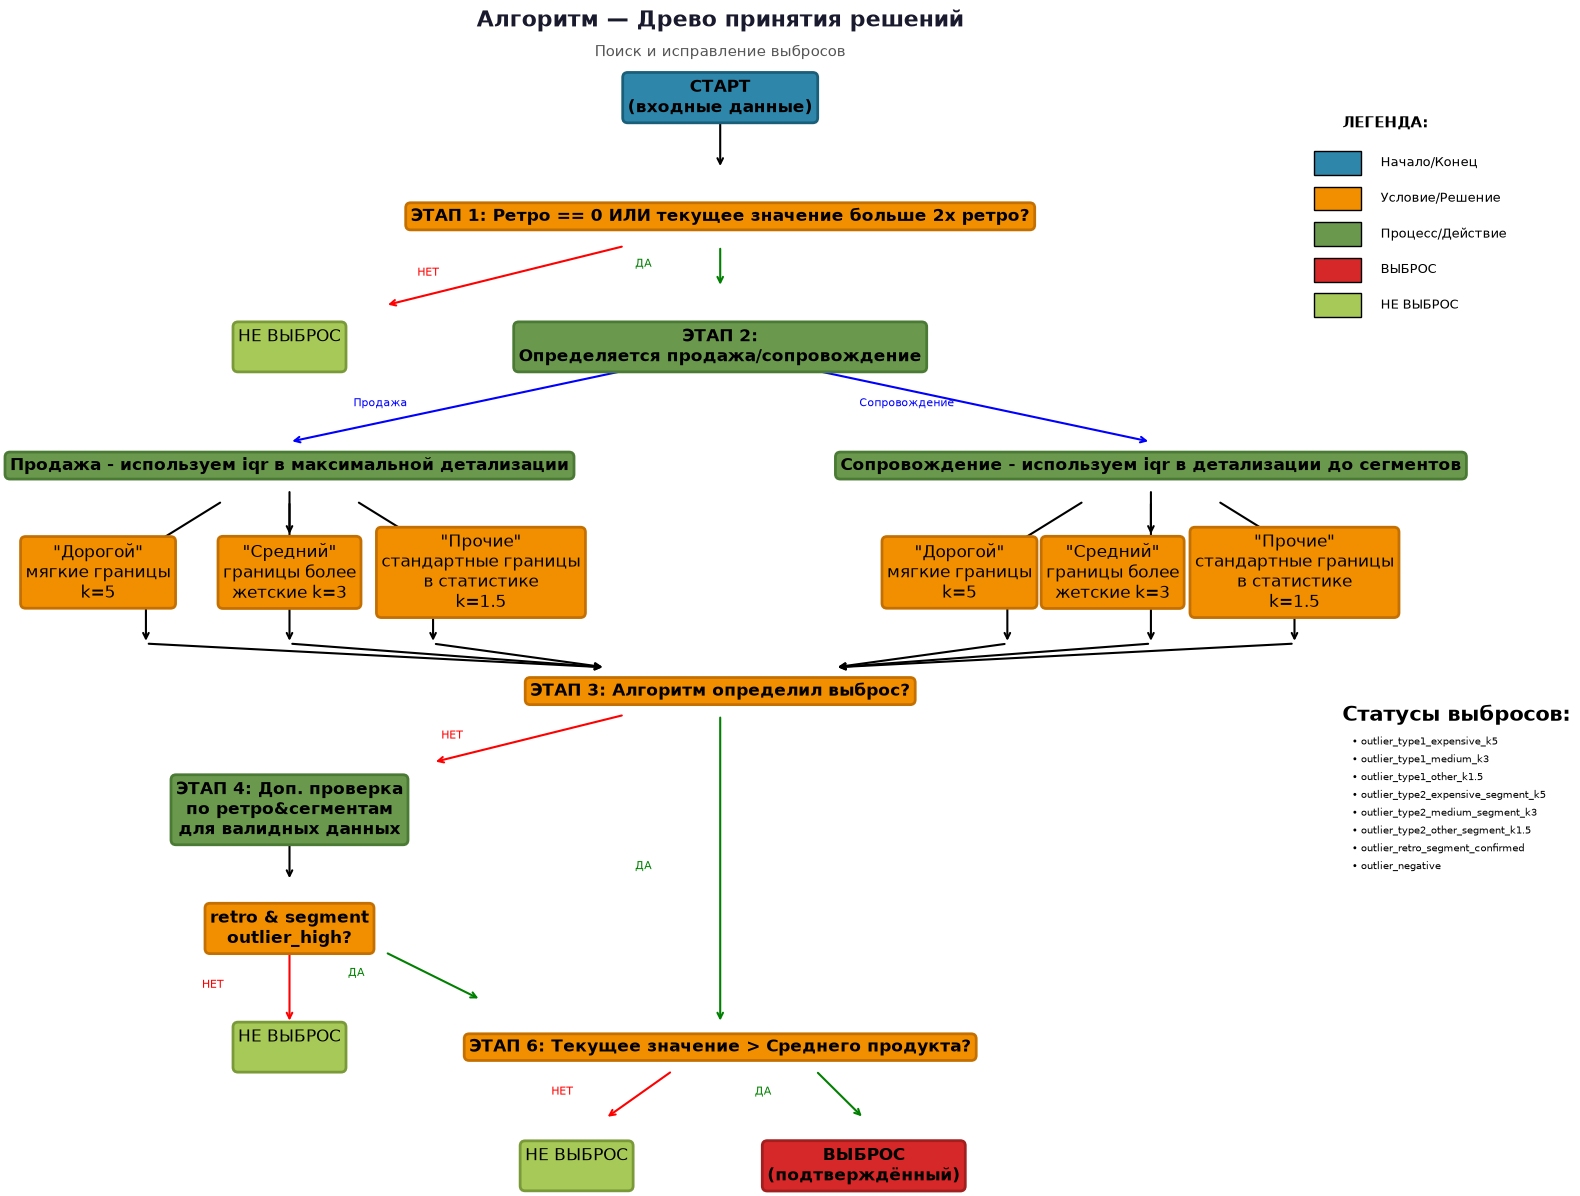

(<Figure size 1600x1200 with 1 Axes>, <Axes: >)

In [21]:
plot_algorithm_tree()

### Функция для устранения выбросов

In [22]:
def fix_outliers(df, 
                 cost_col_incorr='Себестоимость',
                 cost_col='Себестоимость_для_IQR',
                 retro_cost_col='Стоимость ЕРС ретро',
                 replacement_col='Среднее продукт',
                 deal_type_col='Категория расходов',
                 group_col='Группа.Продукт ЕК',
                 segment_col='Сегмент',
                 min_ratio=2.0,
                 k_values=None,
                 category_k_map=None,
                 expensive_segments=None,
                 medium_segments=None):

    # ДЕФОЛТНЫЕ ЗНАЧЕНИЯ, если при вызове функции не передавать переменные


    # ФОРМИРОВАНИЕ ИМЁН КОЛОНОК ИЗ k_values
    
    def k_to_col_suffix(k):
        return str(k)
    
    outlier_cols = {k: f'outlier_k{k_to_col_suffix(k)}' for k in k_values}
    segment_outlier_cols = {k: f'segment_outlier_k{k_to_col_suffix(k)}' for k in k_values}
    retro_outlier_cols = {k: f'retro_outlier_k{k_to_col_suffix(k)}' for k in k_values}
    
    print(f"\n  Колонки для проверки:")
    for k in k_values:
        print(f"    k={k}: {outlier_cols[k]}, {segment_outlier_cols[k]}, {retro_outlier_cols[k]}")
    
    # СОЗДАЁМ КОПИЮ
    
    df_result = df.copy()
    
    # ПРОВЕРКА НАЛИЧИЯ НЕОБХОДИМЫХ КОЛОНОК
    
    if replacement_col not in df_result.columns:
        print(f"ОШИБКА: Отсутствует колонка {replacement_col}")
        return df_result
    
    if retro_cost_col not in df_result.columns:
        print(f"ОШИБКА: Отсутствует колонка {retro_cost_col}")
        return df_result
    
    # Приводим типы
    df_result[deal_type_col] = df_result[deal_type_col].astype(str)
    df_result[segment_col] = df_result[segment_col].astype(str)
    
    expensive_segments_str = [str(s) for s in expensive_segments]
    medium_segments_str = [str(s) for s in medium_segments]
    
    # ПРОВЕРКА НАЛИЧИЯ КОЛОНОК С РАЗНЫМИ k
    
    has_outlier = {k: outlier_cols[k] in df_result.columns for k in k_values}
    has_segment_outlier = {k: segment_outlier_cols[k] in df_result.columns for k in k_values}
    has_retro_outlier = {k: retro_outlier_cols[k] in df_result.columns for k in k_values}
    
    # Логируем отсутствующие колонки
    missing = []
    for k in k_values:
        if not has_outlier[k]:
            missing.append(outlier_cols[k])
        if not has_segment_outlier[k]:
            missing.append(segment_outlier_cols[k])
        if not has_retro_outlier[k]:
            missing.append(retro_outlier_cols[k])
    
    if missing:
        print(f"\n Отсутствуют колонки: {missing}")
    
    # ЭТАП 1: ПРОВЕРКА УСЛОВИЯ
    
    mask_ratio_ok = (
        df_result[retro_cost_col].notna() & 
        (df_result[retro_cost_col] > 0) & 
        (df_result[cost_col] >= df_result[retro_cost_col] * min_ratio)
    )
    
    mask_retro_invalid = (
        df_result[retro_cost_col].isna() |
        (df_result[retro_cost_col] == 0) |
        np.isinf(df_result[retro_cost_col])
    )
    
    mask_condition = mask_ratio_ok | mask_retro_invalid
    
    # ЭТАП 2: ОПРЕДЕЛЕНИЕ КАТЕГОРИИ СЕГМЕНТА
    
    df_result['segment_category'] = 'other'
    df_result.loc[df_result[segment_col].isin(expensive_segments_str), 'segment_category'] = 'expensive'
    df_result.loc[df_result[segment_col].isin(medium_segments_str), 'segment_category'] = 'medium'
    
    mask_type_1 = df_result[deal_type_col] == '1'
    mask_type_2 = df_result[deal_type_col] == '2'
    mask_expensive = df_result['segment_category'] == 'expensive'
    mask_medium = df_result['segment_category'] == 'medium'
    mask_other = df_result['segment_category'] == 'other'
    
    # Получаем k для каждой категории
    k_expensive = category_k_map['expensive']
    k_medium = category_k_map['medium']
    k_other = category_k_map['other']
    

    # ЭТАП 3: ОПРЕДЕЛЕНИЕ ВЫБРОСОВ (ОСНОВНАЯ ЛОГИКА)

    
    print("\n" + "=" * 60)
    print("ЭТАП: Проверка outlier (основная логика)")
    print("=" * 60)
    
    # Инициализация масок
    mask_outlier_type1_expensive = pd.Series(False, index=df_result.index)
    mask_outlier_type1_medium = pd.Series(False, index=df_result.index)
    mask_outlier_type1_other = pd.Series(False, index=df_result.index)
    mask_outlier_type2_expensive = pd.Series(False, index=df_result.index)
    mask_outlier_type2_medium = pd.Series(False, index=df_result.index)
    mask_outlier_type2_other = pd.Series(False, index=df_result.index)
    
    # Тип 1 (Продажа)
    if has_outlier[k_expensive]:
        mask_outlier_type1_expensive = mask_type_1 & mask_expensive & (df_result[outlier_cols[k_expensive]] == 'outlier_high')
    if has_outlier[k_medium]:
        mask_outlier_type1_medium = mask_type_1 & mask_medium & (df_result[outlier_cols[k_medium]] == 'outlier_high')
    if has_outlier[k_other]:
        mask_outlier_type1_other = mask_type_1 & mask_other & (df_result[outlier_cols[k_other]] == 'outlier_high')
    
    # Тип 2 (Сопровождение)
    if has_segment_outlier[k_expensive]:
        mask_outlier_type2_expensive = mask_type_2 & mask_expensive & (df_result[segment_outlier_cols[k_expensive]] == 'outlier_high')
    if has_segment_outlier[k_medium]:
        mask_outlier_type2_medium = mask_type_2 & mask_medium & (df_result[segment_outlier_cols[k_medium]] == 'outlier_high')
    if has_segment_outlier[k_other]:
        mask_outlier_type2_other = mask_type_2 & mask_other & (df_result[segment_outlier_cols[k_other]] == 'outlier_high')
    
    # Объединяем основные выбросы
    mask_outlier_main = (
        mask_outlier_type1_expensive |
        mask_outlier_type1_medium |
        mask_outlier_type1_other |
        mask_outlier_type2_expensive |
        mask_outlier_type2_medium |
        mask_outlier_type2_other
    )
    
    print(f"\n  Основные выбросы по типам и сегментам:")
    if has_outlier[k_expensive]:
        print(f"    - Тип 1 (Продажа) + Дорогой (k{k_expensive}): {mask_outlier_type1_expensive.sum()}")
    if has_outlier[k_medium]:
        print(f"    - Тип 1 (Продажа) + Средний (k{k_medium}): {mask_outlier_type1_medium.sum()}")
    if has_outlier[k_other]:
        print(f"    - Тип 1 (Продажа) + Прочие (k{k_other}): {mask_outlier_type1_other.sum()}")
    if has_segment_outlier[k_expensive]:
        print(f"    - Тип 2 (Сопровождение) + Дорогой (k{k_expensive}): {mask_outlier_type2_expensive.sum()}")
    if has_segment_outlier[k_medium]:
        print(f"    - Тип 2 (Сопровождение) + Средний (k{k_medium}): {mask_outlier_type2_medium.sum()}")
    if has_segment_outlier[k_other]:
        print(f"    - Тип 2 (Сопровождение) + Прочие (k{k_other}): {mask_outlier_type2_other.sum()}")
    
    print(f"\n  Всего основных выбросов: {mask_outlier_main.sum()}")
    
    # ЭТАП 4: ДОПОЛНИТЕЛЬНАЯ ПРОВЕРКА ДЛЯ VALID
    
    # Маска valid для каждой категории сегмента
    if has_outlier[k_expensive]:
        mask_valid_type1_expensive = mask_type_1 & mask_expensive & df_result[outlier_cols[k_expensive]].isin(['','valid'])
    else:
        mask_valid_type1_expensive = pd.Series(False, index=df_result.index)
    
    if has_outlier[k_medium]:
        mask_valid_type1_medium = mask_type_1 & mask_medium & df_result[outlier_cols[k_medium]].isin(['','valid'])
    else:
        mask_valid_type1_medium = pd.Series(False, index=df_result.index)
    
    if has_outlier[k_other]:
        mask_valid_type1_other = mask_type_1 & mask_other & df_result[outlier_cols[k_other]].isin(['','valid'])
    else:
        mask_valid_type1_other = pd.Series(False, index=df_result.index)
    
    if has_segment_outlier[k_expensive]:
        mask_valid_type2_expensive = mask_type_2 & mask_expensive & df_result[segment_outlier_cols[k_expensive]].isin(['','valid'])
    else:
        mask_valid_type2_expensive = pd.Series(False, index=df_result.index)
    
    if has_segment_outlier[k_medium]:
        mask_valid_type2_medium = mask_type_2 & mask_medium & df_result[segment_outlier_cols[k_medium]].isin(['','valid'])
    else:
        mask_valid_type2_medium = pd.Series(False, index=df_result.index)
    
    if has_segment_outlier[k_other]:
        mask_valid_type2_other = mask_type_2 & mask_other & df_result[segment_outlier_cols[k_other]].isin(['','valid'])
    else:
        mask_valid_type2_other = pd.Series(False, index=df_result.index)
    
    mask_valid_combined = (
        mask_valid_type1_expensive | mask_valid_type1_medium | mask_valid_type1_other |
        mask_valid_type2_expensive | mask_valid_type2_medium | mask_valid_type2_other
    )
    
    # Проверка на retro & segment для k_other
    mask_retro_and_segment_outlier = pd.Series(False, index=df_result.index)
    
    if has_retro_outlier[k_other] and has_segment_outlier[k_other]:
        mask_retro_and_segment_outlier = (
            mask_valid_combined &
            (df_result[retro_outlier_cols[k_other]] == 'outlier_high') &
            (df_result[segment_outlier_cols[k_other]] == 'outlier_high')
        )

    # ОБЪЕДИНЕНИЕ ВСЕХ ВЫБРОСОВ
    
    # Все выбросы = основные + дополнительные
    mask_outlier = mask_outlier_main | mask_retro_and_segment_outlier
    
    # ЭТАП 5: ИСКЛЮЧЕНИЕ, ЕСЛИ current < replacement
    
    # Если current < replacement, то это НЕ выброс
    mask_current_less_than_replacement = df_result[cost_col] < df_result[replacement_col]
    
    # Убираем из выбросов те, где current < replacement
    mask_outlier_filtered = mask_outlier & ~mask_current_less_than_replacement
    
    # ИТОГОВЫЙ ВЫБРОС
    
    print("\n" + "=" * 60)
    print("ИТОГОВЫЙ ВЫБРОС")
    print("=" * 60)
    
    # Отрицательная себестоимость
    mask_negative = df_result[cost_col_incorr] < 0
    
    # ИТОГОВЫЙ ВЫБРОС: (условие выполнено) И (outlier обнаружен) И (current >= replacement)
    mask_outlier_final = mask_condition & mask_outlier_filtered
    
    # ВСЕ ВЫБРОСЫ: итоговые + отрицательные
    df_result['is_outlier'] = mask_outlier_final | mask_negative
    df_result['is_confirmed_outlier'] = df_result['is_outlier']
    
    print(f"  Выбросы (условие + outlier + current >= replacement): {mask_outlier_final.sum()}")
    print(f"  Отрицательная себестоимость: {mask_negative.sum()}")
    print(f"  ВСЕГО: {df_result['is_outlier'].sum()}")
    
    # ЕДИНАЯ КОЛОНКА СТАТУСА
    
    df_result['outlier_status'] = 'not_checked'
    
    # === СТАТУСЫ ДЛЯ ВЫБРОСОВ ===
    
    # Тип 1 (Продажа) - основные
    df_result.loc[mask_outlier_final & mask_type_1 & mask_expensive, 'outlier_status'] = f'outlier_type1_expensive_k{k_expensive}'
    df_result.loc[mask_outlier_final & mask_type_1 & mask_medium, 'outlier_status'] = f'outlier_type1_medium_k{k_medium}'
    df_result.loc[mask_outlier_final & mask_type_1 & mask_other, 'outlier_status'] = f'outlier_type1_other_k{k_other}'
    
    # Тип 2 (Сопровождение) - основные
    df_result.loc[mask_outlier_final & mask_type_2 & mask_expensive, 'outlier_status'] = f'outlier_type2_expensive_segment_k{k_expensive}'
    df_result.loc[mask_outlier_final & mask_type_2 & mask_medium, 'outlier_status'] = f'outlier_type2_medium_segment_k{k_medium}'
    df_result.loc[mask_outlier_final & mask_type_2 & mask_other, 'outlier_status'] = f'outlier_type2_other_segment_k{k_other}'
    
    # Дополнительные выбросы (valid + retro & segment)
    df_result.loc[mask_outlier_final & mask_retro_and_segment_outlier, 'outlier_status'] = 'outlier_retro_segment_confirmed'
    
    # Отрицательная себестоимость
    df_result.loc[mask_negative, 'outlier_status'] = 'outlier_negative'
    
    # СТАТУСЫ ДЛЯ НЕ ВЫБРОСОВ
    
    # 1. Исключено из-за current < replacement
    mask_excluded_by_replacement = (mask_outlier & mask_current_less_than_replacement) & ~mask_negative
    df_result.loc[mask_excluded_by_replacement, 'outlier_status'] = 'not_outlier_current_less_than_replacement'
    
    # 2. Условие НЕ выполнено (current <= 2x retro)
    mask_not_ratio = ~mask_condition & ~mask_retro_invalid
    df_result.loc[mask_not_ratio & ~mask_negative, 'outlier_status'] = 'not_outlier_ratio_failed'
    
    # 3. Условие выполнено (retro invalid), но выброс НЕ обнаружен
    mask_retro_invalid_no_outlier = mask_retro_invalid & ~mask_outlier & ~mask_negative
    df_result.loc[mask_retro_invalid_no_outlier, 'outlier_status'] = 'not_outlier_invalid_retro'
    
    # 4. Условие выполнено (ratio ok), но выброс НЕ обнаружен
    mask_ratio_ok_no_outlier = mask_ratio_ok & ~mask_outlier & ~mask_negative
    df_result.loc[mask_ratio_ok_no_outlier, 'outlier_status'] = 'not_outlier_ratio_ok'
    
    # 5. Outlier обнаружен, но условие НЕ выполнено → НЕ ВЫБРОС
    mask_outlier_no_condition = mask_outlier & ~mask_condition & ~mask_negative & ~mask_current_less_than_replacement
    df_result.loc[mask_outlier_no_condition, 'outlier_status'] = 'not_outlier_condition_failed'
    
    # ЗАМЕНА

    df_result['cost_fixed'] = df_result[cost_col].copy()
    df_result['replacement_source'] = 'original'
    
    mask_replace = df_result['is_outlier']
    df_result.loc[mask_replace, 'cost_fixed'] = df_result.loc[mask_replace, replacement_col]
    df_result.loc[mask_replace, 'replacement_source'] = 'вариант_1'
    
    mask_invalid_replacement = mask_replace & (df_result[replacement_col].isna() | np.isinf(df_result[replacement_col]))
    df_result.loc[mask_invalid_replacement, 'replacement_source'] = 'no_valid_replacement'
    
    # ИТОГИ

    
    print("\n" + "=" * 60)
    print("РЕЗУЛЬТАТ")
    print("=" * 60)
    
    print(f"\nВсего записей: {len(df_result)}")
    print(f"Подтверждённых выбросов: {df_result['is_outlier'].sum()}")
    print(f"Исправлено выбросов: {(df_result['replacement_source'] != 'original').sum()}")
    
    
    return df_result

In [23]:
df_result = fix_outliers(df_result,k_values=k_values,category_k_map=category_k_map,expensive_segments=expensive_segments,medium_segments=medium_segments)


  Колонки для проверки:
    k=1.75: outlier_k1.75, segment_outlier_k1.75, retro_outlier_k1.75
    k=3: outlier_k3, segment_outlier_k3, retro_outlier_k3
    k=6: outlier_k6, segment_outlier_k6, retro_outlier_k6

ЭТАП: Проверка outlier (основная логика)

  Основные выбросы по типам и сегментам:
    - Тип 1 (Продажа) + Дорогой (k6): 0
    - Тип 1 (Продажа) + Средний (k3): 0
    - Тип 1 (Продажа) + Прочие (k1.75): 0
    - Тип 2 (Сопровождение) + Дорогой (k6): 0
    - Тип 2 (Сопровождение) + Средний (k3): 0
    - Тип 2 (Сопровождение) + Прочие (k1.75): 0

  Всего основных выбросов: 0

ИТОГОВЫЙ ВЫБРОС
  Выбросы (условие + outlier + current >= replacement): 12
  Отрицательная себестоимость: 0
  ВСЕГО: 12

РЕЗУЛЬТАТ

Всего записей: 32
Подтверждённых выбросов: 12
Исправлено выбросов: 12


In [24]:
output_file = 'Итого анализ выбросов.xlsx'
df_result.to_excel(output_file, index=False)
print(f"\nРезультаты сохранены в {output_file}")


Результаты сохранены в Итого анализ выбросов.xlsx


In [25]:
print(df_result.columns.tolist())
print("Количество строк:", len(df_result))

['Группа. Продукт ЕК', 'Группа текст', 'Драйвер', 'Драйвер текст', 'Категория расходов', 'Сегмент', 'Сегмент текст', 'Канал продажи', 'Канал продажи текст', 'Расход, руб.', 'Драйвер,шт.', 'Стоимость ЕРС', 'Группы для каналов', 'Стоимость ЕРС ретро', 'Себестоимость', 'Среднее продукт', 'Среднее сегмент', 'Себестоимость_для_IQR', 'is_excluded_segment', 'n_obs', 'has_enough_data', 'q1', 'q3', 'iqr', 'lower_bound_k1.75', 'upper_bound_k1.75', 'lower_bound_k3', 'upper_bound_k3', 'lower_bound_k6', 'upper_bound_k6', 'outlier_k1.75', 'outlier_k3', 'outlier_k6', 'n_obs_segment', 'has_enough_data_segment', 'q1_segment', 'q3_segment', 'iqr_segment', 'segment_lower_bound_k1.75', 'segment_upper_bound_k1.75', 'segment_lower_bound_k3', 'segment_upper_bound_k3', 'segment_lower_bound_k6', 'segment_upper_bound_k6', 'segment_outlier_k1.75', 'segment_outlier_k3', 'segment_outlier_k6', 'n_obs_retro', 'has_enough_data_retro', 'q1_retro', 'q3_retro', 'iqr_retro', 'retro_lower_bound_k1.75', 'retro_upper_bound_

In [27]:
print("Всего записей:", len(df_result))

print(
    "Потенциальных аномалий:",
    df_result["is_outlier"].fillna(False).astype(bool).sum()
)

print(
    "Подтверждённых аномалий:",
    df_result["is_confirmed_outlier"].fillna(False).astype(bool).sum()
)

print(
    "Фактически изменённых значений:",
    (
        df_result["Себестоимость"].notna()
        & df_result["cost_fixed"].notna()
        & df_result["Себестоимость"].ne(df_result["cost_fixed"])
    ).sum()
)

Всего записей: 32
Потенциальных аномалий: 12
Подтверждённых аномалий: 12
Фактически изменённых значений: 12
